# 03 - Split and Preprocessing

Create the fixed exact-content-grouped split and demonstrate reference-CNN preprocessing on a small training-partition sample. Retain all labelled images. No raw files, test images, augmentation, models or training are used.

## 1. Project root and audited inputs

Use the existing root-detection convention. Read IDs and all original manifest fields as strings. Reuse the saved image audit rather than decoding the full dataset again.

In [1]:
from pathlib import Path
from datetime import datetime
from importlib.metadata import version
import hashlib
import json
import math
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")

def find_project_root(start):
    start=Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").is_file() and (candidate / "notebooks/00_Environment_Check.ipynb").is_file():
            return candidate
    raise FileNotFoundError("Open this project root or its notebooks directory.")

PROJECT_ROOT=find_project_root(Path.cwd())
assert find_project_root(PROJECT_ROOT / "notebooks") == PROJECT_ROOT
assert find_project_root(PROJECT_ROOT) == PROJECT_ROOT
assert Path(sys.prefix).resolve() == PROJECT_ROOT / ".venv"
assert Path(sys.executable).resolve().parent == PROJECT_ROOT / ".venv/Scripts"
MANIFEST_PATH=PROJECT_ROOT / "data/processed/training_manifest.csv"
SPLIT_PATH=PROJECT_ROOT / "data/processed/split_manifest.csv"
MAPPING_PATH=PROJECT_ROOT / "data/processed/class_mapping.json"
EVIDENCE_PATH=PROJECT_ROOT / "outputs/metrics/split_preprocessing_check.json"
PREVIEW_PATH=PROJECT_ROOT / "outputs/figures/preprocessing_preview.png"
TRAIN_DIR=(PROJECT_ROOT / "data/raw/train/train").resolve()
SEED=42
VALIDATION_FRACTION=0.20
checks={}

def require(name, condition):
    checks[name]=bool(condition)
    assert checks[name], name
    print(name + ": PASS")

def read_strings(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False, na_filter=False)

manifest=read_strings(MANIFEST_PATH)
labels=read_strings(PROJECT_ROOT / "data/raw/train_labels.csv")
audit=json.loads((PROJECT_ROOT / "outputs/metrics/training_data_audit.json").read_text(encoding="utf-8"))
duplicate_memberships=read_strings(PROJECT_ROOT / "outputs/metrics/training_duplicate_groups.csv")
classes=sorted(manifest["class"].unique().tolist())
require("audited_rows_retained_in_original_order", manifest[["image_id", "class"]].equals(labels) and len(manifest)==audit["training_rows"])
require("unique_original_ids", manifest["image_id"].is_unique)
require("eight_exact_classes", len(classes)==8 and classes==sorted(item["class"] for item in audit["class_distribution"]))
require("all_rows_successfully_decoded", manifest["decode_status"].isin(["ok", "warning"]).all())
require("complete_hashes", all(manifest[column].str.fullmatch(r"[0-9a-f]{64}").all() for column in ["pixel_sha256", "byte_sha256"]))
require("paths_are_original_training_images", manifest["image_path"].equals("data/raw/train/train/" + manifest["image_id"] + ".jpg"))
print("Python:", sys.executable)


audited_rows_retained_in_original_order: PASS
unique_original_ids: PASS
eight_exact_classes: PASS
all_rows_successfully_decoded: PASS
complete_hashes: PASS
paths_are_original_training_images: PASS
Python: C:\Users\leoca\Kaggle-Competition\.venv\Scripts\python.exe


## 2. Fixed group-stratified 80/20 split

Use `pixel_sha256` directly as the group ID. Require one class per group, then sort the one-row-per-group table lexicographically by the full hash. Call `train_test_split` once with stratification by class, `test_size=0.20`, and `random_state=42`. Group sizes differ, so image-level proportions are approximately 80/20. Numeric IDs are not source/animal groups, and no seeds are searched.

An existing split is checked against the deterministic result and all original manifest fields. A mismatch raises an error and leaves the existing split unchanged.

In [2]:
require("one_class_per_pixel_group", manifest.groupby("pixel_sha256")["class"].nunique().eq(1).all())
group_table=(manifest.groupby("pixel_sha256", sort=True)
             .agg(label=("class", "first"), image_count=("image_id", "size"))
             .reset_index().rename(columns={"pixel_sha256": "group_id", "label": "class"})
             .sort_values("group_id", kind="stable").reset_index(drop=True))
train_groups, validation_groups=train_test_split(
    group_table, test_size=VALIDATION_FRACTION, random_state=SEED, stratify=group_table["class"]
)
partition={group_id: "train" for group_id in train_groups["group_id"]}
partition.update({group_id: "validation" for group_id in validation_groups["group_id"]})
split_manifest=manifest.copy()
split_manifest["group_id"]=manifest["pixel_sha256"]
split_manifest["split"]=split_manifest["group_id"].map(partition)
require("all_rows_assigned_once", len(split_manifest)==len(manifest) and split_manifest["split"].isin(["train", "validation"]).all())
require("original_manifest_fields_unchanged", split_manifest[manifest.columns].equals(manifest))
require("pixel_groups_assigned_wholly", split_manifest.groupby("group_id")["split"].nunique().eq(1).all())
train_rows=split_manifest[split_manifest["split"].eq("train")]
validation_rows=split_manifest[split_manifest["split"].eq("validation")]
require("all_classes_in_both_partitions", set(train_rows["class"])==set(classes)==set(validation_rows["class"]))
crossings={}
for column in ["image_id", "pixel_sha256", "byte_sha256"]:
    crossings[column]=len(set(train_rows[column]) & set(validation_rows[column]))
    require(column + "_does_not_cross_partitions", crossings[column]==0)
# Confirm the previously saved duplicate memberships also remain intact.
joined=duplicate_memberships.merge(split_manifest[["image_id", "class", "split"]], on=["image_id", "class"], how="left", validate="many_to_one")
require("saved_duplicate_groups_do_not_cross", joined["split"].notna().all() and joined.groupby(["duplicate_type", "group_id"])["split"].nunique().eq(1).all())

def save_or_verify_split(candidate, path):
    if path.exists():
        saved=read_strings(path)
        if list(saved.columns)!=list(candidate.columns) or not saved["image_id"].is_unique:
            raise ValueError("Existing split schema/IDs differ; it has not been overwritten.")
        expected=candidate.set_index("image_id").sort_index()
        actual=saved.set_index("image_id").sort_index()
        if not actual.equals(expected):
            raise ValueError("Existing split differs from the fixed deterministic result; it has not been overwritten.")
        return "verified_existing"
    candidate.to_csv(path, index=False, mode="x")
    return "created"

split_action=save_or_verify_split(split_manifest, SPLIT_PATH)
saved_split=read_strings(SPLIT_PATH)
require("saved_split_exact_fields_and_membership", saved_split.set_index("image_id").sort_index().equals(split_manifest.set_index("image_id").sort_index()))
per_class=(pd.crosstab(split_manifest["class"], split_manifest["split"])
           .reindex(index=classes, columns=["train", "validation"], fill_value=0))
per_class["total"]=per_class["train"]+per_class["validation"]
per_class["train_within_class_pct"]=100*per_class["train"]/per_class["total"]
per_class["validation_within_class_pct"]=100*per_class["validation"]/per_class["total"]
per_class["train_partition_class_pct"]=100*per_class["train"]/len(train_rows)
per_class["validation_partition_class_pct"]=100*per_class["validation"]/len(validation_rows)
print("Groups:",len(group_table),"train:",len(train_groups),"validation:",len(validation_groups))
print("Images:",len(train_rows),"train and",len(validation_rows),"validation")
print("Image-level validation proportion:",len(validation_rows)/len(manifest))
display(per_class.round(4))


one_class_per_pixel_group: PASS


all_rows_assigned_once: PASS
original_manifest_fields_unchanged: PASS
pixel_groups_assigned_wholly: PASS
all_classes_in_both_partitions: PASS
image_id_does_not_cross_partitions: PASS
pixel_sha256_does_not_cross_partitions: PASS


byte_sha256_does_not_cross_partitions: PASS
saved_duplicate_groups_do_not_cross: PASS


saved_split_exact_fields_and_membership: PASS
Groups: 63645 train: 50916 validation: 12729
Images: 50927 train and 12733 validation
Image-level validation proportion: 0.20001570845114672


split,train,validation,total,train_within_class_pct,validation_within_class_pct,train_partition_class_pct,validation_partition_class_pct
class,,,,,,,
CatEye,11105,2779,13884,79.9842,20.0158,21.8057,21.8252
CatFace,5553,1389,6942,79.9914,20.0086,10.9038,10.9087
CatMouth,5554,1388,6942,80.0058,19.9942,10.9058,10.9008
CatNose,5554,1388,6942,80.0058,19.9942,10.9058,10.9008
DogEye,9265,2315,11580,80.0086,19.9914,18.1927,18.1811
DogFace,4632,1158,5790,80.0000,20.0000,9.0954,9.0945
DogMouth,4632,1158,5790,80.0000,20.0000,9.0954,9.0945
DogNose,4632,1158,5790,80.0000,20.0000,9.0954,9.0945


## 3. Class encoding

Sort the exact class spellings and assign indices 0-7. JSON object keys are strings, so `index_to_class` uses keys `"0"` through `"7"`. Verify all round trips and reject any incompatible existing mapping.

In [3]:
class_to_index={label: index for index, label in enumerate(classes)}
index_to_class={str(index): label for label, index in class_to_index.items()}
mapping={"class_to_index":class_to_index, "index_to_class":index_to_class}
require("class_encoding_round_trips", all(index_to_class[str(class_to_index[label])]==label for label in classes))
require("class_indices_are_zero_to_seven", sorted(class_to_index.values())==list(range(8)))
if MAPPING_PATH.exists():
    if json.loads(MAPPING_PATH.read_text(encoding="utf-8"))!=mapping:
        raise ValueError("Existing class mapping differs; it has not been overwritten.")
    mapping_action="verified_existing"
else:
    with MAPPING_PATH.open("x", encoding="utf-8") as stream:
        stream.write(json.dumps(mapping, indent=2)+"\n")
    mapping_action="created"
require("saved_mapping_matches", json.loads(MAPPING_PATH.read_text(encoding="utf-8"))==mapping)
print(json.dumps(mapping, indent=2))


class_encoding_round_trips: PASS
class_indices_are_zero_to_seven: PASS
saved_mapping_matches: PASS
{
  "class_to_index": {
    "CatEye": 0,
    "CatFace": 1,
    "CatMouth": 2,
    "CatNose": 3,
    "DogEye": 4,
    "DogFace": 5,
    "DogMouth": 6,
    "DogNose": 7
  },
  "index_to_class": {
    "0": "CatEye",
    "1": "CatFace",
    "2": "CatMouth",
    "3": "CatNose",
    "4": "DogEye",
    "5": "DogFace",
    "6": "DogMouth",
    "7": "DogNose"
  }
}


## 4. Reference-CNN preprocessing

Load RGB, resize the longest side to 224 pixels using Pillow bilinear interpolation, and centre-pad with RGB(128,128,128). Each resized side is rounded to the nearest integer with ties rounded up, with a minimum of one pixel. This preserves aspect ratio up to unavoidable integer rounding. The longest side is always 224, including when upscaling tiny images.

Padding is split with floor division on the left/top; any odd extra pixel goes to the right/bottom. Convert uint8 pixels to a contiguous float32 `[3,224,224]` tensor and divide by 255 exactly once. Padding therefore becomes 128/255, not 0.5. No cropping, stretching, augmentation, EXIF rotation or raw-file writes occur. Pretrained-model normalisation is deferred.

In [4]:
TARGET=224
PAD_RGB=(128,128,128)

def resize_geometry(width, height):
    longest=max(width, height)
    # Exact integer equivalent of floor(side * TARGET / longest + 0.5).
    new_width=max(1, (2*width*TARGET+longest)//(2*longest))
    new_height=max(1, (2*height*TARGET+longest)//(2*longest))
    left=(TARGET-new_width)//2
    top=(TARGET-new_height)//2
    return {
        "resized_width":new_width, "resized_height":new_height,
        "left":left, "top":top,
        "right":TARGET-new_width-left, "bottom":TARGET-new_height-top,
    }

def training_image_path(relative_path):
    path=(PROJECT_ROOT / relative_path).resolve()
    if path.parent!=TRAIN_DIR:
        raise ValueError("Only original training-image paths are allowed.")
    return path

def reference_preprocess(relative_path):
    """Read one training image on demand; return its tensor and geometry."""
    with Image.open(training_image_path(relative_path)) as image:
        image.load()
        with image.convert("RGB") as rgb:
            geometry=resize_geometry(rgb.width, rgb.height)
            resized=rgb.resize((geometry["resized_width"],geometry["resized_height"]), resample=Image.Resampling.BILINEAR)
            with resized, Image.new("RGB", (TARGET,TARGET), PAD_RGB) as canvas:
                canvas.paste(resized, (geometry["left"],geometry["top"]))
                pixels=np.array(canvas, dtype=np.uint8, copy=True)
    tensor=torch.from_numpy(pixels).permute(2,0,1).contiguous().to(torch.float32)
    tensor.div_(255.0)
    return tensor, geometry

# Cheap geometry examples exercise odd padding and minimum-side rounding.
require("odd_padding_goes_right_or_bottom", resize_geometry(224,223)["top"]==0 and resize_geometry(224,223)["bottom"]==1 and resize_geometry(223,224)["right"]==1)
require("very_thin_images_keep_at_least_one_pixel", resize_geometry(1,10000)["resized_width"]==1)
require("half_up_rounding", resize_geometry(448,3)["resized_height"]==2)


odd_padding_goes_right_or_bottom: PASS
very_thin_images_keep_at_least_one_pixel: PASS
half_up_rounding: PASS


## 5. Small training-partition sample and preview

Use the first ID per class after sorting, plus the two smallest images by area and the minimum/maximum aspect-ratio examples from the training partition. Ties use image ID order. Reuse an image if it meets several criteria, recording every reason. Repeated preprocessing must give exactly equal tensors. Only this small sample is decoded; no resized dataset is saved.

preview_uses_training_partition_only: PASS
preview_includes_every_class: PASS


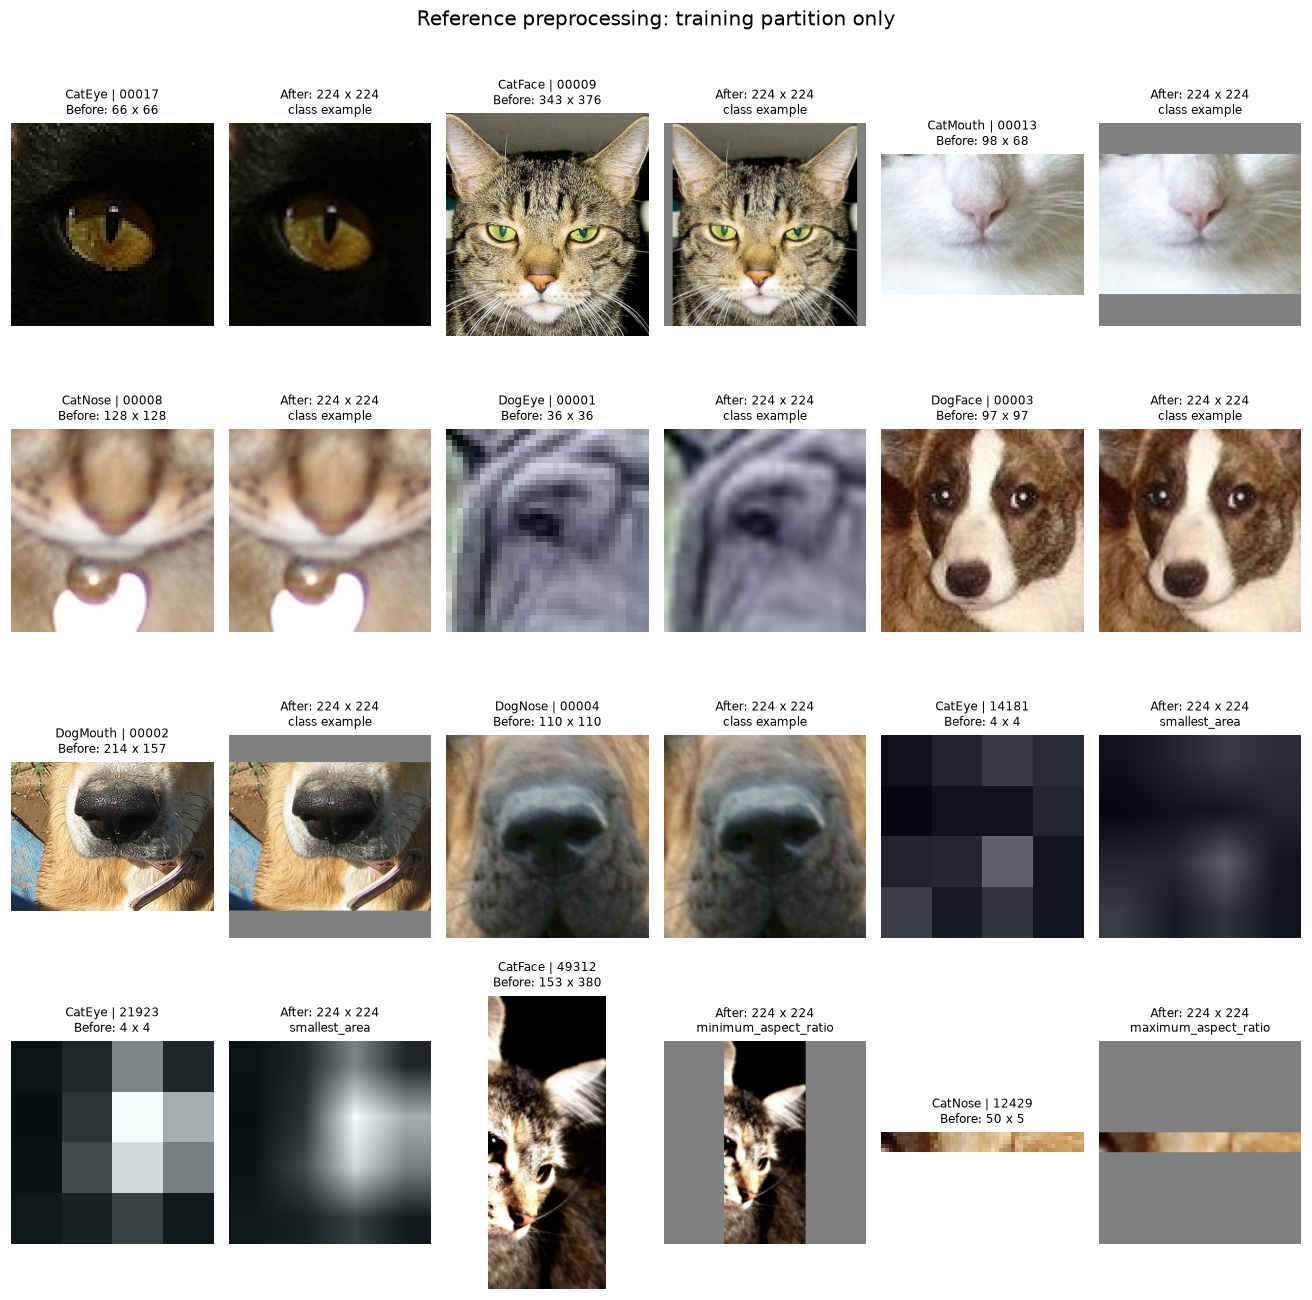

all_sample_tensor_and_encoding_checks: PASS


,image_id,class,original_width,original_height
0,00017,CatEye,66,66
1,00009,CatFace,343,376
2,00013,CatMouth,98,68
3,00008,CatNose,128,128
4,00001,DogEye,36,36
5,00003,DogFace,97,97
6,00002,DogMouth,214,157
7,00004,DogNose,110,110
8,14181,CatEye,4,4
9,21923,CatEye,4,4


In [5]:
selection=train_rows.copy()
selection["numeric_width"]=selection["width"].astype(int)
selection["numeric_height"]=selection["height"].astype(int)
selection["area"]=selection["numeric_width"]*selection["numeric_height"]
selection["aspect_ratio"]=selection["numeric_width"]/selection["numeric_height"]
selection=selection.sort_values("image_id", kind="stable")
reasons={}
def add_sample(image_id, reason):
    reasons.setdefault(image_id, []).append(reason)
for label in classes:
    add_sample(selection.loc[selection["class"].eq(label),"image_id"].iloc[0], "class_example:"+label)
for image_id in selection.sort_values(["area","image_id"],kind="stable").head(2)["image_id"]:
    add_sample(image_id,"smallest_area")
add_sample(selection.sort_values(["aspect_ratio","image_id"],kind="stable")["image_id"].iloc[0],"minimum_aspect_ratio")
add_sample(selection.sort_values(["aspect_ratio","image_id"],ascending=[False,True],kind="stable")["image_id"].iloc[0],"maximum_aspect_ratio")
sample=selection.set_index("image_id").loc[list(reasons)].reset_index()
require("preview_uses_training_partition_only", sample["split"].eq("train").all())
require("preview_includes_every_class", set(sample["class"])==set(classes))

plt.rcParams.update({"font.size":9,"figure.dpi":110,"savefig.dpi":150})
fig,axes=plt.subplots(math.ceil(len(sample)/3),6,figsize=(12,3*math.ceil(len(sample)/3)),squeeze=False)
sample_results=[]
for position,row in enumerate(sample.to_dict("records")):
    tensor,geometry=reference_preprocess(row["image_path"])
    repeated,repeated_geometry=reference_preprocess(row["image_path"])
    fill=torch.tensor(128,dtype=torch.float32)/255
    padding_ok=True
    for region in [tensor[:,:geometry["top"],:], tensor[:,TARGET-geometry["bottom"]:,:], tensor[:,:,:geometry["left"]], tensor[:,:,TARGET-geometry["right"]:]]:
        padding_ok &= bool(torch.all(region==fill))
    outcomes={
        "shape":list(tensor.shape)==[3,224,224], "dtype":tensor.dtype==torch.float32,
        "finite":bool(torch.isfinite(tensor).all()),
        "range_0_to_1":float(tensor.min())>=0 and float(tensor.max())<=1,
        "deterministic":torch.equal(tensor,repeated) and geometry==repeated_geometry,
        "padding_rgb128_scaled_once":padding_ok,
        "longest_side_224":max(geometry["resized_width"],geometry["resized_height"])==224,
        "class_round_trip":index_to_class[str(class_to_index[row["class"]])]==row["class"],
    }
    sample_results.append({"image_id":row["image_id"],"class":row["class"],"class_index":class_to_index[row["class"]],
                           "reasons":reasons[row["image_id"]],"original_width":int(row["width"]),"original_height":int(row["height"]),
                           "geometry":geometry,"tensor_min":float(tensor.min()),"tensor_max":float(tensor.max()),"checks":outcomes})
    panel_row,pair=divmod(position,3)
    before,after=axes[panel_row,2*pair:2*pair+2]
    with Image.open(training_image_path(row["image_path"])) as original:
        original.load()
        with original.convert("RGB") as rgb:
            before.imshow(np.asarray(rgb),aspect="equal")
    before.set_title(f"{row['class']} | {row['image_id']}\nBefore: {row['width']} x {row['height']}",fontsize=8)
    after.imshow(tensor.permute(1,2,0).numpy(),aspect="equal")
    after.set_title("After: 224 x 224\n"+", ".join(reasons[row["image_id"]]).replace("class_example:"+row["class"],"class example"),fontsize=8)
    before.axis("off")
    after.axis("off")
for unused in range(2*len(sample),axes.size):
    axes.flat[unused].axis("off")
fig.suptitle("Reference preprocessing: training partition only",fontsize=13)
fig.tight_layout(rect=(0,0,1,0.97))
fig.savefig(PREVIEW_PATH)
plt.show()
plt.close(fig)
require("all_sample_tensor_and_encoding_checks", all(all(result["checks"].values()) for result in sample_results))
display(pd.DataFrame([{key:item[key] for key in ["image_id","class","original_width","original_height"]} for item in sample_results]))


## 6. Persist verification evidence

Save actual image/group counts, per-class counts and proportions, encoding, preprocessing settings and checks. Exact-content disjointness does not rule out unidentified related crops or animals crossing partitions. No source groups are inferred from filenames.

In [6]:
# Exercise the existing-file rerun path without recreating the split.
before_bytes=SPLIT_PATH.read_bytes()
require("rerun_verifies_membership_without_rewriting", save_or_verify_split(split_manifest,SPLIT_PATH)=="verified_existing" and SPLIT_PATH.read_bytes()==before_bytes)
# A deliberately changed in-memory candidate must be rejected without touching disk.
changed=split_manifest.copy()
changed.loc[0,"split"]="validation" if changed.loc[0,"split"]=="train" else "train"
mismatch_rejected=False
try:
    save_or_verify_split(changed,SPLIT_PATH)
except ValueError:
    mismatch_rejected=True
require("different_existing_membership_is_rejected_unchanged", mismatch_rejected and SPLIT_PATH.read_bytes()==before_bytes)
require("requested_outputs_exist", all(path.is_file() and path.stat().st_size>0 for path in [SPLIT_PATH,MAPPING_PATH,PREVIEW_PATH]))
source_digest=hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()
summary={
    "checked_at":datetime.now().astimezone().isoformat(),
    "seed":SEED,
    "splitting_method":{
        "function":"sklearn.model_selection.train_test_split", "group_identifier":"pixel_sha256",
        "group_table_order":"full pixel SHA-256 ascending, one row per group", "stratify":"group class",
        "test_size":VALIDATION_FRACTION, "random_state":SEED, "seed_search":False,
        "image_level_proportions":"Approximately 80/20 because exact-content groups can have multiple images.",
        "sklearn_version":version("scikit-learn"),
    },
    "source_manifest_sha256":source_digest,
    "rows":{"total":len(manifest),"train":len(train_rows),"validation":len(validation_rows)},
    "groups":{"total":len(group_table),"train":len(train_groups),"validation":len(validation_groups)},
    "achieved_proportions":{
        "train_images":len(train_rows)/len(manifest), "validation_images":len(validation_rows)/len(manifest),
        "train_groups":len(train_groups)/len(group_table), "validation_groups":len(validation_groups)/len(group_table),
    },
    "per_class":json.loads(per_class.reset_index().to_json(orient="records")),
    "cross_partition_overlap_counts":crossings,
    "mapping":mapping,
    "preprocessing":{
        "purpose":"reference CNN; pretrained-model normalisation deferred", "input_mode":"RGB",
        "target_size":[224,224], "resize":"longest side to 224, including upscaling", "interpolation":"Pillow Image.Resampling.BILINEAR",
        "rounding":"nearest integer, ties up: max(1,(2*side*224+longest)//(2*longest))",
        "padding_rgb":[128,128,128], "padding_placement":"centred, odd extra pixel on right/bottom",
        "tensor_shape":[3,224,224], "tensor_dtype":"torch.float32", "scale":"uint8 to float32, divide by 255 once",
        "range":[0,1], "augmentation":False, "crop":False, "raw_files_modified":False,
        "pillow_version":version("Pillow"), "torch_version":torch.__version__,
    },
    "sample_selection":"training partition; first sorted ID per class, two smallest areas and min/max aspect ratios; ties by ID",
    "sample_checks":sample_results,
    "file_actions":{"split_manifest":split_action,"class_mapping":mapping_action},
    "checks":checks,"failed_checks":[name for name,passed in checks.items() if not passed],
    "limitations":[
        "No reliable animal/source groups are available; numeric IDs are not used as provenance groups.",
        "Unidentified related crops, animals and near-duplicates may remain across partitions despite zero exact-hash overlap.",
        "Tiny and elongated images are retained; upscaling cannot recover missing detail and padding can occupy much of the tensor.",
    ],
    "outputs":[path.relative_to(PROJECT_ROOT).as_posix() for path in [SPLIT_PATH,MAPPING_PATH,PREVIEW_PATH,EVIDENCE_PATH]],
    "execution":{"python_executable":sys.executable,"kernel_name":"enge707-assessment3","working_directory":str(Path.cwd())},
}
EVIDENCE_PATH.write_text(json.dumps(summary,indent=2)+"\n",encoding="utf-8")
require("saved_evidence_readable", json.loads(EVIDENCE_PATH.read_text(encoding="utf-8"))["rows"]==summary["rows"])
# Include the final readability check in the evidence too.
summary["checks"]=checks
EVIDENCE_PATH.write_text(json.dumps(summary,indent=2)+"\n",encoding="utf-8")
print("Saved:",EVIDENCE_PATH.relative_to(PROJECT_ROOT))
print("All split and preprocessing checks passed.")


rerun_verifies_membership_without_rewriting: PASS


different_existing_membership_is_rejected_unchanged: PASS
requested_outputs_exist: PASS
saved_evidence_readable: PASS
Saved: outputs\metrics\split_preprocessing_check.json
All split and preprocessing checks passed.
